In [1]:
import cv2
import numpy as np
from numpy import ndarray
import matplotlib.pyplot as plt
from PIL import Image
from PIL.ExifTags import TAGS

def read_hdr(image_path: str) -> ndarray:
    """
    Read HDR image and convert it to the proper RGB layout.
    """
    hdr_image = cv2.imread(
        filename=image_path,
        flags=cv2.IMREAD_ANYDEPTH | cv2.IMREAD_COLOR
    )
    hdr_image = cv2.cvtColor(hdr_image, cv2.COLOR_BGR2RGB)
    return hdr_image

def get_exif(image_path: str) -> dict:
    """
    Read metadata from the image.
    Interesting values: "ExposureTime", "FNumber"
    """
    image = Image.open(image_path)
    info = image._getexif()

    if info is None:
        raise ValueError(f"Missing metadata for image {image_path}")
    exif_data = {}
    for tag, value in info.items():
        decoded = TAGS.get(tag)
        if not decoded:
            continue
        exif_data[decoded] = value
    return exif_data

def _calculate_luminance(hdr_image):
    return (0.2126 * hdr_image[:, :, 0] +
            0.7152 * hdr_image[:, :, 1] +
            0.0722 * hdr_image[:, :, 2])

def _filter_pixels(luminance, epsilon):
    return luminance[luminance > epsilon]

def measure_ev_range(hdr_image, epsilon=1e-6) -> float:
    """
    Measure dynamic range for HDR file.
    """
    valid_pixels = _filter_pixels(
        luminance=_calculate_luminance(hdr_image),
        epsilon=epsilon
    )
    luminance_max = np.max(valid_pixels)
    luminance_min = np.min(valid_pixels)
    
    return np.log2(luminance_max / luminance_min)

def tone_map_reinhard(hdr_image: ndarray) -> ndarray:
    """
    Tonemapping Reinhard's operator.
    """
    tonemap_operator = cv2.createTonemapReinhard(
        gamma=2.2,
        intensity=0.0,
        light_adapt=0.0,
        color_adapt=0.0
    )
    result = tonemap_operator.process(src=hdr_image)
    return result

HDR_PATH = "Bracketed_images/C07/DSC02486.JPG"
LDR_PATH = "Bracketed_images/C07/DSC02486.JPG"

if __name__ == "__main__":
    # read LDR image and show metadata
    metadata = get_exif(LDR_PATH)
    print(f"Exposure Time: {metadata.get('ExposureTime')}")
    print(f"FNumber: {metadata.get('FNumber')}")
    
    # read HDR image and calculate Dynamic Range
    hdr_img = read_hdr(HDR_PATH)
    print(f"Data type: {hdr_img.dtype}")
    print(f"Range: {hdr_img.min()} do {hdr_img.max()}")
    print(f"Dynamic Range: {measure_ev_range(hdr_img)}")

    # tonemap HDR image and show it on the screen
    gamma_corrected = tone_map_reinhard(hdr_img)
    plt.imshow(gamma_corrected)
    plt.show()

Exposure Time: 0.025
FNumber: 1.8
Data type: uint8
Range: 0 do 255
Dynamic Range: 10.786210789521137


error: OpenCV(4.13.0) /Users/xperience/GHA-OpenCV-Python/_work/opencv-python/opencv-python/opencv/modules/photo/src/tonemap.cpp:69: error: (-215:Assertion failed) _src.dims() == 2 && _src.type() == CV_32FC3 in function 'process'


In [26]:
import os
import cv2
import torch
import numpy as np
import math
import random
from torch.utils.data import Dataset
from PIL import Image
from PIL.ExifTags import TAGS
import torchvision.transforms.functional as TF

class HDREyeDataset(Dataset):
    def __init__(self, root_dir, target_size=(256, 256), train=True):
        self.root_dir = root_dir
        self.target_size = target_size
        self.train = train
        
        if not os.path.exists(root_dir):
            raise FileNotFoundError(f"Ścieżka {root_dir} nie istnieje!")
            
        all_scenes = sorted([s for s in os.listdir(root_dir) if os.path.isdir(os.path.join(root_dir, s))])
        
        # Podział na zbiór treningowy i testowy (zgodnie z instrukcją)
        if self.train:
            self.scenes = [s for s in all_scenes if not ("C40" <= s <= "C46")]
        else:
            self.scenes = [s for s in all_scenes if ("C40" <= s <= "C46")]

    def __len__(self):
        return len(self.scenes)

    def get_exif(self, image_path):
        try:
            image = Image.open(image_path)
            info = image._getexif()
            if info is None: return None
            return {TAGS.get(tag): value for tag, value in info.items() if TAGS.get(tag)}
        except:
            return None

    def find_best_ev(self, scene_path, img_files):
        exposures = []
        for f in img_files:
            exif = self.get_exif(os.path.join(scene_path, f))
            if exif and 'ExposureTime' in exif:
                t = float(exif['ExposureTime'])
                exposures.append((f, t))
        
        # Fallback jeśli nie ma EXIF
        if len(exposures) < 3:
            img_files.sort()
            return img_files[len(img_files)//2], img_files[0], img_files[-1]

        exposures.sort(key=lambda x: x[1])
        base_img, base_t = exposures[len(exposures)//2]
        
        under_img, over_img = exposures[0][0], exposures[-1][0]
        min_diff_under, min_diff_over = float('inf'), float('inf')

        for f, t in exposures:
            ev_diff = math.log2(t / base_t)
            if abs(ev_diff - (-2.7)) < min_diff_under:
                min_diff_under = abs(ev_diff - (-2.7))
                under_img = f
            if abs(ev_diff - 2.7) < min_diff_over:
                min_diff_over = abs(ev_diff - 2.7)
                over_img = f
        return base_img, under_img, over_img

    def _load_img(self, path):
        img = cv2.imread(path)
        if img is None: raise FileNotFoundError(path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, self.target_size)
        img = img.astype(np.float32) / 255.0
        # Konwersja na tensor (HWC -> CHW) za pomocą PyTorch
        return torch.from_numpy(img.transpose((2, 0, 1)))

    def __getitem__(self, idx):
        scene_path = os.path.join(self.root_dir, self.scenes[idx])
        img_files = sorted([f for f in os.listdir(scene_path) if f.lower().endswith(('.jpg', '.jpeg'))])
        
        base_f, under_f, over_f = self.find_best_ev(scene_path, img_files)
        
        img_ldr = self._load_img(os.path.join(scene_path, base_f))
        img_under = self._load_img(os.path.join(scene_path, under_f))
        img_over = self._load_img(os.path.join(scene_path, over_f))
        
        target = torch.cat((img_under, img_over), dim=0)

        # Augmentacja tylko dla treningu
        if self.train:
            if random.random() > 0.5:
                img_ldr = TF.hflip(img_ldr)
                target = TF.hflip(target)
            if random.random() > 0.5:
                img_ldr = TF.vflip(img_ldr)
                target = TF.vflip(target)
                
        return img_ldr, target

In [29]:
dataset = HDREyeDataset(data_path, train=True)
train_loader = DataLoader(dataset, batch_size=4, shuffle=True)

In [28]:
from torchvision import transforms
import os

transform = transforms.Compose([
    transforms.ToTensor(),
])
# Ścieżka do Twoich danych
data_path = '/Users/mariannajacyna/sigk-lab21/Bracketed_images'

# Inicjalizacja datasetu
# target_size ustawiamy na 256x256, bo sieci U-Net lubią potęgi dwójki
dataset = HDREyeDataset(root_dir=data_path, transform=transform, target_size=(256, 256))

print(f"Znaleziono scen do trenowania: {len(dataset.scenes)}")
print(f"Przykładowa scena: {dataset.scenes[0]}")

TypeError: __init__() got an unexpected keyword argument 'transform'

In [35]:
import torch.nn as nn
import torch

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(0.2, inplace=True), # ZMIANA: LeakyReLU zamiast ReLU
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(0.2, inplace=True)  # ZMIANA: LeakyReLU zamiast ReLU
        )
    def forward(self, x):
        return self.conv(x)

class ExposureSynthesizer(nn.Module):
    def __init__(self):
        super(ExposureSynthesizer, self).__init__()
        # Encoder
        self.inc = DoubleConv(3, 64)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))
        
        # Decoder
        self.up1 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(256, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(128, 64)
        
        # Output: 6 kanałów (3 dla under, 3 dla over)
        self.outc = nn.Conv2d(64, 6, kernel_size=1)
        # USUNIĘTO self.sigmoid - zastąpimy go funkcją clamp w forward

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        
        x = self.up1(x3)
        x = torch.cat([x, x2], dim=1)
        x = self.conv_up1(x)
        
        x = self.up2(x)
        x = torch.cat([x, x1], dim=1)
        x = self.conv_up2(x)
        
        logits = self.outc(x)
        # ZMIANA: clamp zapewnia zakres [0,1] bez spłaszczania gradientów
        return torch.clamp(logits, 0, 1)

In [31]:
# Sprawdzenie dostępności Metal Performance Shaders (MPS)
if torch.backends.mps.is_available():
    device = torch.device("mps")
    print("Urządzenie: M3 (MPS)")
else:
    device = torch.device("cpu")
    print("Urządzenie: CPU (brak wsparcia MPS)")

# Przeniesienie modelu na M3
model = ExposureSynthesizer().to(device)

# Optymalizator i funkcja straty
optimizer = torch.optim.Adam(model.parameters(), lr=0.0004)
criterion = nn.MSELoss() # Dobra do zachowania kolorów i krawędzi

# DataLoader dla Twoich 33 scen
train_loader = DataLoader(dataset, batch_size=4, shuffle=True)

Urządzenie: M3 (MPS)


In [33]:

# Pobranie jednej paczki danych
inputs, targets = next(iter(train_loader))

print(f"Dane na wejściu (min/max): {inputs.min():.2f} / {inputs.max():.2f}")
print(f"Dane docelowe (min/max): {targets.min():.2f} / {targets.max():.2f}")

# Jeśli wartości są w zakresie 0-1, wszystko jest w porządku!

Dane na wejściu (min/max): 0.00 / 1.00
Dane docelowe (min/max): 0.00 / 1.00


In [32]:
def visualize_progress(model, input_batch, target_batch, epoch, device):
    model.eval()
    with torch.no_grad():
        # Pobieramy pierwszy obraz z batcha
        inp = input_batch[0:1].to(device)
        tar = target_batch[0:1].to(device)
        
        # Generujemy predykcję
        out = model(inp)
        
        # Konwersja na numpy do wyświetlenia
        def to_img(t):
            return t.squeeze().permute(1, 2, 0).cpu().numpy()

        plt.figure(figsize=(15, 5))
        
        plt.subplot(1, 3, 1)
        plt.imshow(to_img(out[:, :3, :, :]))
        plt.title(f"Wygenerowany Under (EV -2.7)\nEpoka {epoch}")
        plt.axis('off')
        
        plt.subplot(1, 3, 2)
        plt.imshow(to_img(inp))
        plt.title("Oryginalny LDR (Wejście)")
        plt.axis('off')
        
        plt.subplot(1, 3, 3)
        plt.imshow(to_img(out[:, 3:, :, :]))
        plt.title(f"Wygenerowany Over (EV +2.7)\nEpoka {epoch}")
        plt.axis('off')
        
        plt.show()
    model.train()

Trening na mps...
Epoka [1/150], Loss: 0.3582, LR: 0.0005


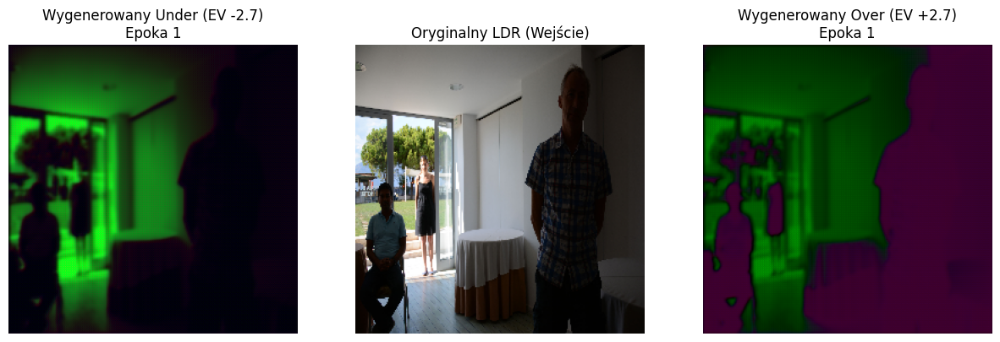

Epoka [10/150], Loss: 0.2064, LR: 0.0005
Epoka [20/150], Loss: 0.1724, LR: 0.0005


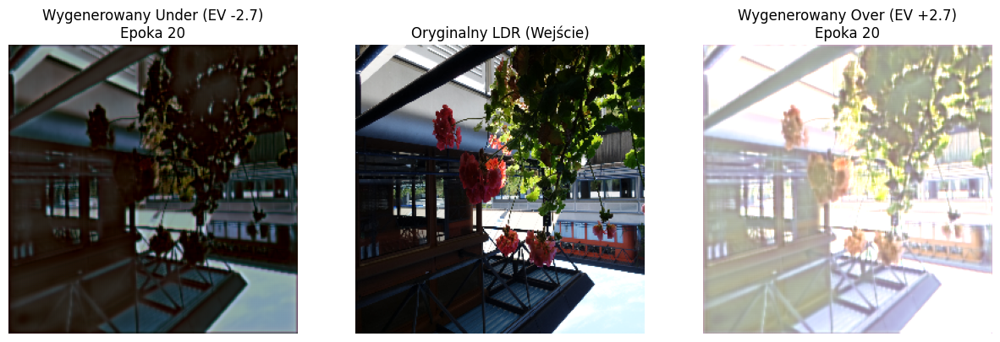

Epoka [30/150], Loss: 0.1938, LR: 0.0005
Epoka [40/150], Loss: 0.1542, LR: 0.0005


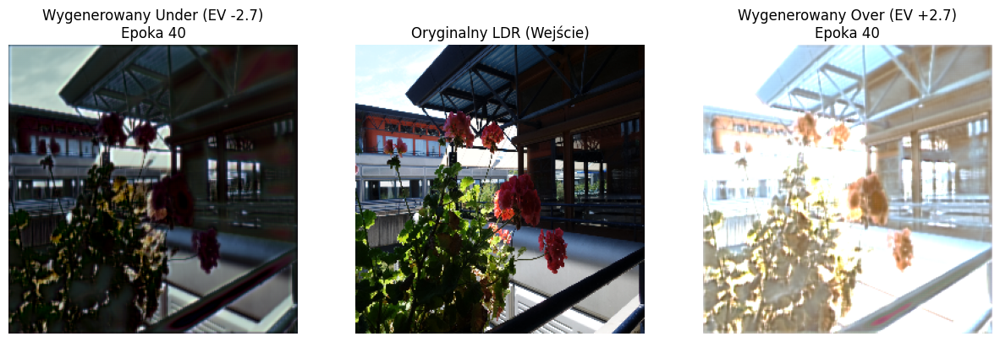

Epoka [50/150], Loss: 0.1652, LR: 0.0005
Epoka [60/150], Loss: 0.1423, LR: 0.0005


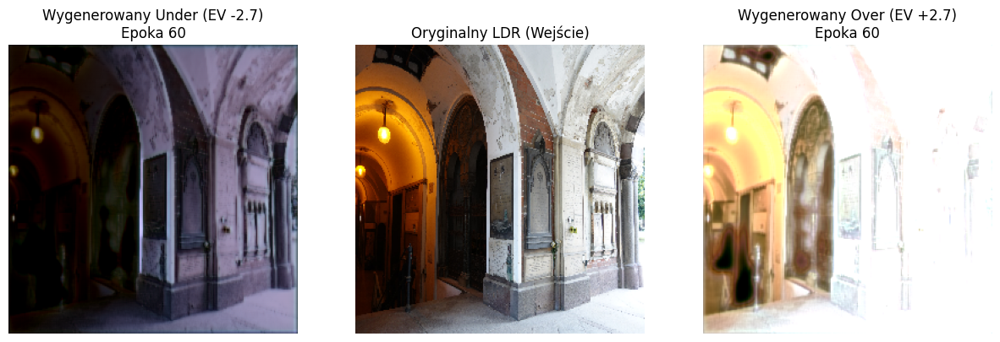

Epoka [70/150], Loss: 0.1395, LR: 0.00025
Epoka [80/150], Loss: 0.1317, LR: 0.00025


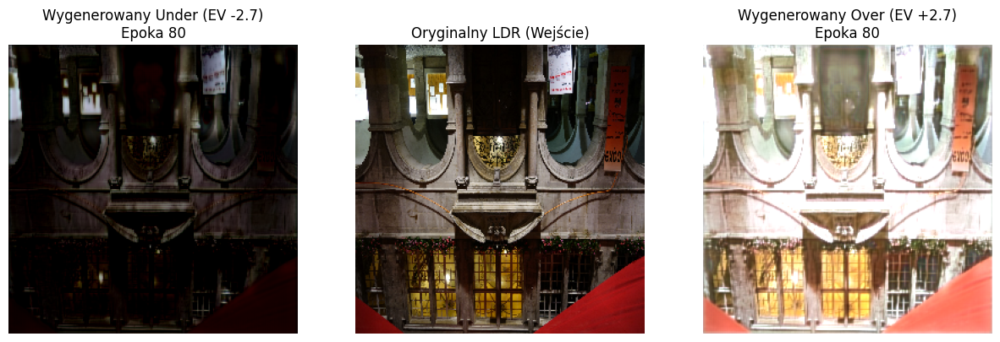

Epoka [90/150], Loss: 0.1278, LR: 0.00025
Epoka [100/150], Loss: 0.1273, LR: 0.000125


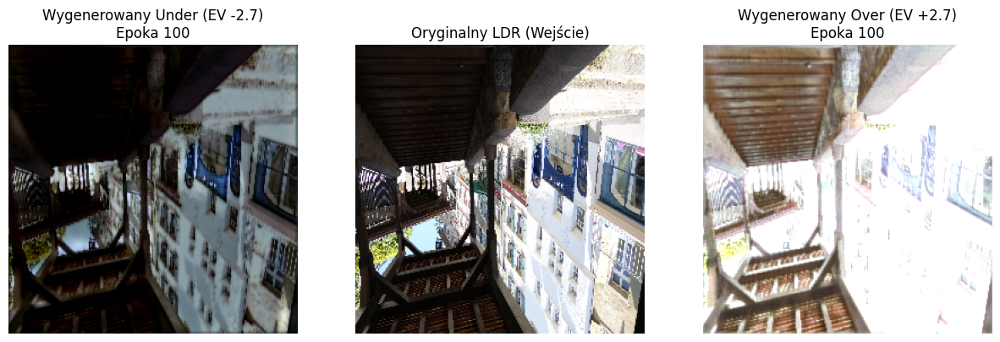

Epoka [110/150], Loss: 0.1216, LR: 0.000125
Epoka [120/150], Loss: 0.1280, LR: 0.000125


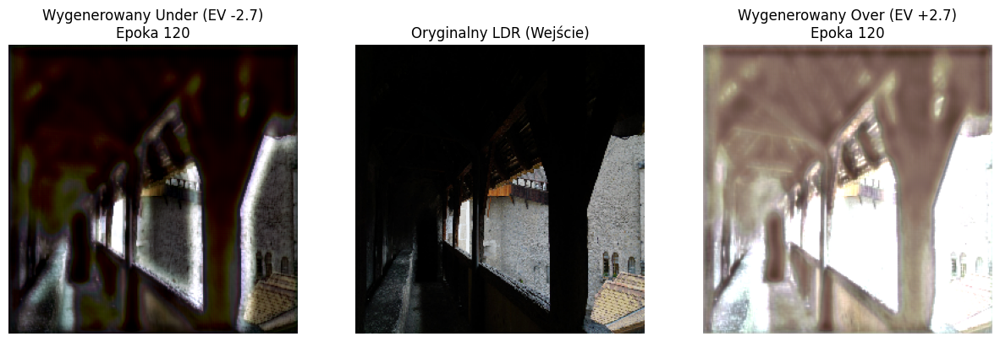

Epoka [130/150], Loss: 0.1193, LR: 6.25e-05
Epoka [140/150], Loss: 0.1179, LR: 6.25e-05


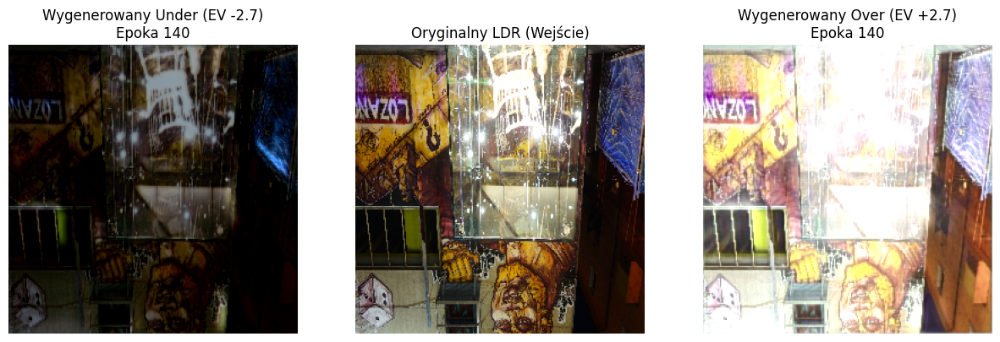

Epoka [150/150], Loss: 0.1159, LR: 3.125e-05
Trening zakończony sukcesem!


In [36]:
import torch.optim as optim

# Parametry
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
model = ExposureSynthesizer().to(device)
criterion = nn.L1Loss() # ZMIANA: L1Loss zamiast MSE
optimizer = optim.Adam(model.parameters(), lr=0.0005)

# ZMIANA: Scheduler zmniejszy LR, gdy nauka stanie w miejscu
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=10, factor=0.5)

num_epochs = 150 # ZMIANA: Więcej epok dla lepszych detali
train_loader = DataLoader(HDREyeDataset(data_path, train=True), batch_size=4, shuffle=True)

print(f"Trening na {device}...")
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
    
    avg_loss = running_loss / len(train_loader)
    scheduler.step(avg_loss) # Aktualizacja schedulera
    
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoka [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}, LR: {optimizer.param_groups[0]['lr']}")
        # Wywołaj swoją funkcję visualize_progress tutaj
    if (epoch + 1) % 20 == 0 or epoch == 0:
        # Przekazujemy ostatni batch do podglądu
        visualize_progress(model, inputs, targets, epoch + 1, device)

print("Trening zakończony sukcesem!")

In [37]:
import cv2
import numpy as np
import lpips

# Inicjalizacja metryki LPIPS (używamy vgg dla dokładności)
loss_fn_lpips = lpips.LPIPS(net='vgg').to(device)

def calculate_psnr(img1, img2):
    # img1, img2 powinny być w formacie [0, 1]
    return cv2.PSNR(img1.cpu().numpy(), img2.cpu().numpy())

def calculate_lpips(img1, img2):
    # LPIPS oczekuje tensorów w zakresie [-1, 1]
    img1_norm = (img1 * 2) - 1
    img2_norm = (img2 * 2) - 1
    return loss_fn_lpips(img1_norm, img2_norm).item()

Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]


/Users/mariannajacyna/Library/Python/3.9/lib/python/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/mariannajacyna/Library/Python/3.9/lib/python/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /Users/mariannajacyna/Library/Python/3.9/lib/python/site-packages/lpips/weights/v0.1/vgg.pth


In [38]:
# Zapisywanie wag modelu do pliku .pth
torch.save(model.state_dict(), 'exposure_synthesizer.pth')
print("Model został zapisany pomyślnie!")

Model został zapisany pomyślnie!


In [12]:
# 1. Stworzenie nowej instancji klasy
model = ExposureSynthesizer().to(device)

# 2. Wczytanie wag z pliku
model.load_state_dict(torch.load('exposure_synthesizer.pth', map_location=device))

# 3. Przełączenie w tryb ewaluacji (ważne przed testami!)
model.eval()
print("Model został wczytany i jest gotowy do testów!")

Model został wczytany i jest gotowy do testów!


In [39]:
def read_hdr(image_path: str) -> np.ndarray:
    # Odczyt obrazu HDR z zachowaniem głębi bitowej
    hdr_image = cv2.imread(filename=image_path, flags=cv2.IMREAD_ANYDEPTH | cv2.IMREAD_COLOR)
    return cv2.cvtColor(hdr_image, cv2.COLOR_BGR2RGB)

def _calculate_luminance(hdr_image):
    # Obliczanie luminancji na podstawie wag RGB
    return (0.2126 * hdr_image[:, :, 0] + 0.7152 * hdr_image[:, :, 1] + 0.0722 * hdr_image[:, :, 2])

def measure_ev_range(hdr_image, epsilon=1e-6) -> float:
    # Pomiar zakresu dynamicznego w jednostkach EV
    luminance = _calculate_luminance(hdr_image)
    valid_pixels = luminance[luminance > epsilon]
    if len(valid_pixels) == 0: return 0
    return np.log2(np.max(valid_pixels) / np.min(valid_pixels))

Przetwarzanie scen testowych...
Max under: 1.0, Max over: 1.0


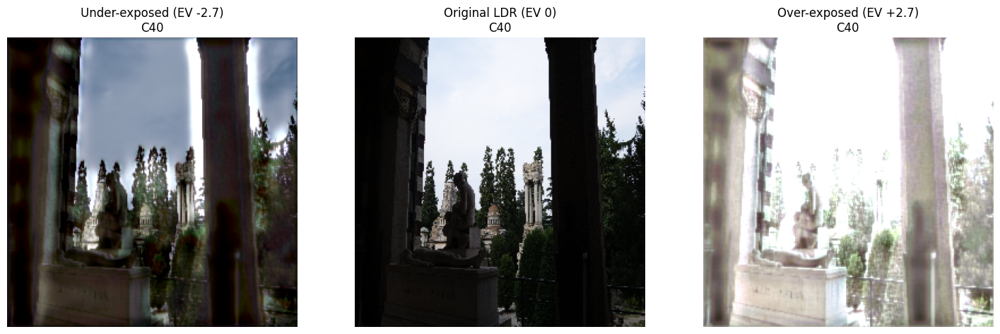

Max under: 1.0, Max over: 1.0


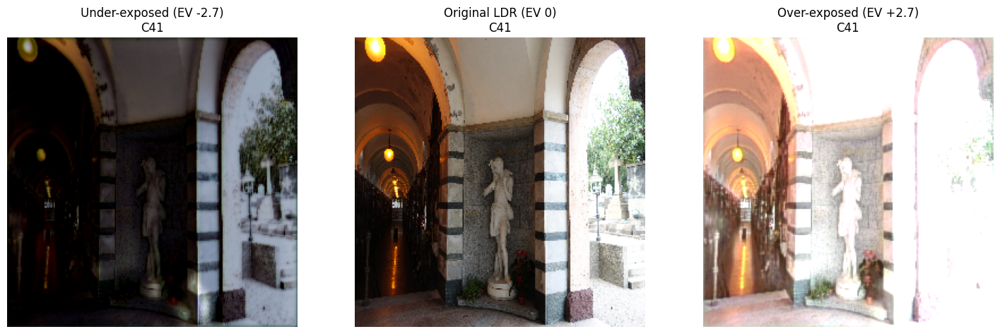

Ostrzeżenie: Brak EXIF dla DSC03976.JPG_crop.jpg w scenie C42. Używam domyślnego czasu 1/100.
Max under: 1.0, Max over: 1.0


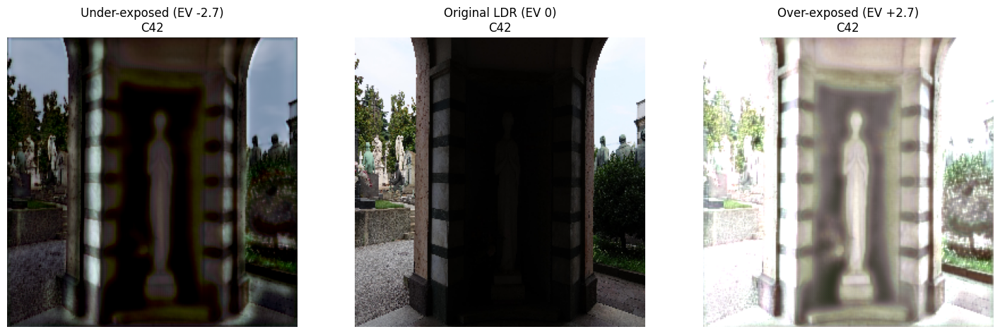

Max under: 1.0, Max over: 1.0


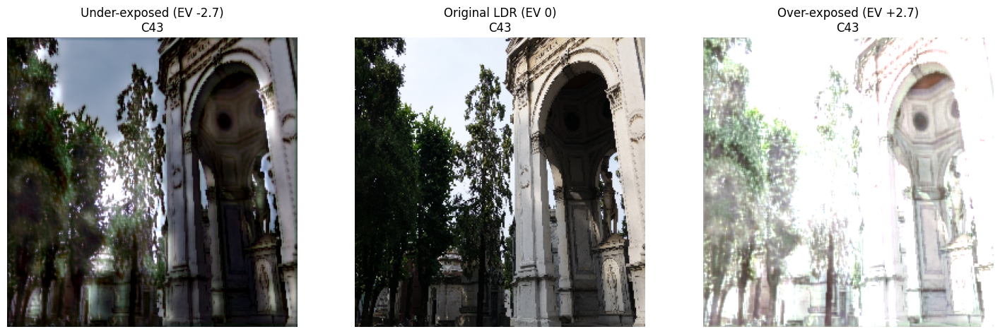

Ostrzeżenie: Brak EXIF dla DSC04012.JPG_crop.jpg w scenie C44. Używam domyślnego czasu 1/100.
Max under: 1.0, Max over: 1.0


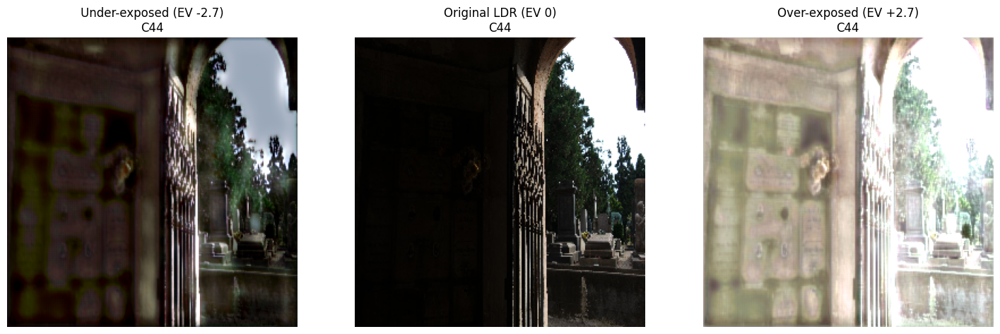

Ostrzeżenie: Brak EXIF dla DSC04069.JPG_crop.jpg w scenie C45. Używam domyślnego czasu 1/100.
Max under: 1.0, Max over: 1.0


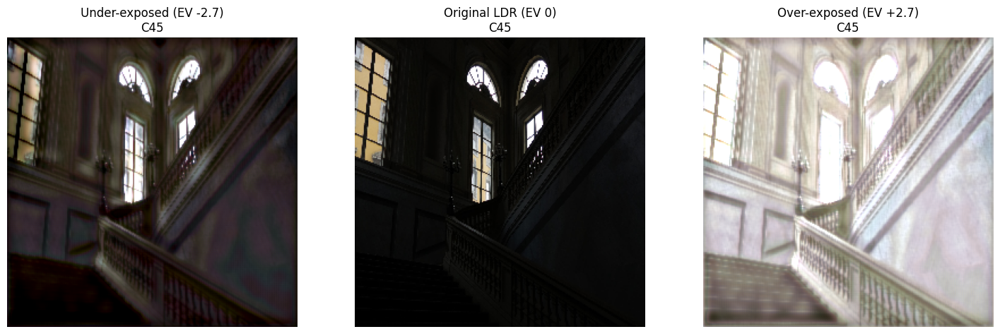

Ostrzeżenie: Brak EXIF dla DSC04102.JPG_crop.jpg w scenie C46. Używam domyślnego czasu 1/100.
Max under: 1.0, Max over: 1.0


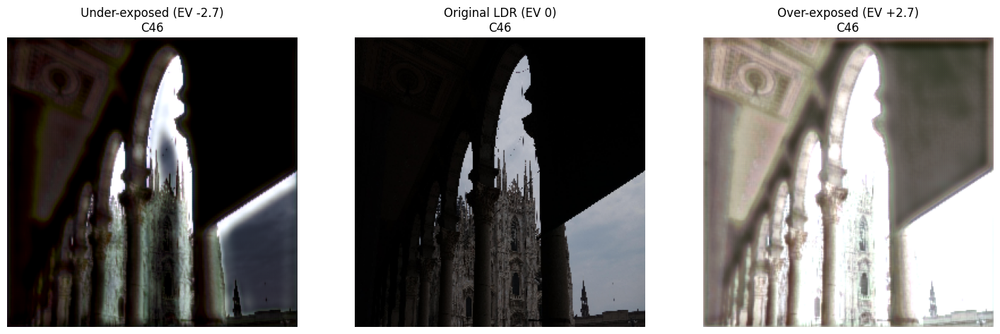

Gotowe! Możesz teraz wyświetlić tabele.


In [ ]:
import pandas as pd
import math

# Konfiguracja ścieżek
data_path = '/Users/mariannajacyna/sigk-lab21/Bracketed_images'
hdr_base_path = '/Users/mariannajacyna/sigk-lab21/HDR' 
test_scenes = [f"C{i}" for i in range(40, 47)] # Zdjęcia testowe C40-C46 [cite: 17, 105]

# Przygotowanie struktur na dane
t1_results = []
t2_results = []

model.eval() # Tryb ewaluacji
print("Przetwarzanie scen testowych...")
import matplotlib.pyplot as plt

def debug_visualize(ldr_tensor, under_tensor, over_tensor, scene_name=""):
    # Konwersja z tensorów [1, 3, H, W] na obrazy numpy [H, W, 3]
    def to_img(t):
        return t.squeeze().permute(1, 2, 0).cpu().detach().numpy()

    plt.figure(figsize=(18, 6))
    
    # 1. Obraz niedoświetlony (wygenerowany)
    plt.subplot(1, 3, 1)
    plt.imshow(to_img(under_tensor))
    plt.title(f"Under-exposed (EV -2.7)\n{scene_name}")
    plt.axis('off')
    
    # 2. Obraz oryginalny (LDR)
    plt.subplot(1, 3, 2)
    plt.imshow(to_img(ldr_tensor))
    plt.title(f"Original LDR (EV 0)\n{scene_name}")
    plt.axis('off')
    
    # 3. Obraz prześwietlony (wygenerowany)
    plt.subplot(1, 3, 3)
    plt.imshow(to_img(over_tensor))
    plt.title(f"Over-exposed (EV +2.7)\n{scene_name}")
    plt.axis('off')
    
    plt.show()

# Wywołanie wewnątrz Twojej pętli testowej:

with torch.no_grad():
    for scene in test_scenes:
        scene_path = os.path.join(data_path, scene)
        if not os.path.exists(scene_path): continue
        
        
        # 1. Pobranie plików przy użyciu Twojego Datasetu
        img_files = sorted([f for f in os.listdir(scene_path) if f.lower().endswith(('.jpg', '.jpeg'))])
        base_f, under_gt_f, over_gt_f = dataset.find_best_ev(scene_path, img_files)
        
        # 2. Wczytanie obrazów (LDR i Ground Truth dla EV +/- 2.7) [cite: 14]
        ldr_in = dataset._load_img(os.path.join(scene_path, base_f)).unsqueeze(0).to(device)
        under_gt = dataset._load_img(os.path.join(scene_path, under_gt_f)).unsqueeze(0).to(device)
        over_gt = dataset._load_img(os.path.join(scene_path, over_gt_f)).unsqueeze(0).to(device)
        
        # 3. Generowanie ekspozycji przez model
        outputs = model(ldr_in)
        under_gen = outputs[:, :3, :, :]
        over_gen = outputs[:, 3:, :, :]
        
        # 4. Obliczanie PSNR i LPIPS dla Tabeli 1 
        def get_score(gen, gt):
            psnr = 10 * math.log10(1.0 / torch.mean((gen - gt)**2).item())
            lp = loss_fn_lpips(gen*2-1, gt*2-1).item()
            return psnr, lp

        psnr_u, lp_u = get_score(under_gen, under_gt)
        psnr_o, lp_o = get_score(over_gen, over_gt)
        
        t1_results.append(["underexposed", psnr_u, lp_u])
        t1_results.append(["overexposed", psnr_o, lp_o])
        
        # 5. Rekonstrukcja HDR algorytmem Debeveca 
        def to_cv2_uint8(t):
            return (t.squeeze().permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
        
        # Przygotowanie listy obrazów i czasów naświetlania 
        images_for_hdr = [to_cv2_uint8(under_gen), to_cv2_uint8(ldr_in), to_cv2_uint8(over_gen)]
        
        # 5. Rekonstrukcja HDR algorytmem Debeveca [cite: 13-14]
        exif_data = dataset.get_exif(os.path.join(scene_path, base_f))
        
        # Sprawdzenie czy metadane istnieją, jeśli nie - użyj domyślnego czasu (np. 1/100)
        if exif_data is not None and 'ExposureTime' in exif_data:
            t_base = float(exif_data['ExposureTime'])
        else:
            print(f"Ostrzeżenie: Brak EXIF dla {base_f} w scenie {scene}. Używam domyślnego czasu 1/100.")
            t_base = 0.01 
            
        # Czasy naświetlenia dla EV -2.7, 0, +2.7 
        times = np.array([t_base / (2**2.7), t_base, t_base * (2**2.7)], dtype=np.float32)
        # Czasy dla EV -2.7, 0, +2.7
        times = np.array([t_base / (2**2.7), t_base, t_base * (2**2.7)], dtype=np.float32)
        
        print(f"Max under: {under_gen.max()}, Max over: {over_gen.max()}")
        merge_debevec = cv2.createMergeDebevec()
        hdr_new = merge_debevec.process(images_for_hdr, times)
        
        # 6. Porównanie zakresu dynamicznego (Tabela 2) 
        dr_new = measure_ev_range(hdr_new)
        debug_visualize(ldr_in, under_gen, over_gen, scene_name=scene)
        # Wczytanie oryginału HDR
        hdr_orig_file = os.path.join(hdr_base_path, f"{scene}_HDR.hdr")
        dr_orig = 0
        if os.path.exists(hdr_orig_file):
            hdr_orig = read_hdr(hdr_orig_file)
            dr_orig = measure_ev_range(hdr_orig)
            
        t2_results.append([scene, dr_orig, dr_new])

print("Gotowe! Możesz teraz wyświetlić tabele.")

In [42]:
df1 = pd.DataFrame(t1_results, columns=["Metoda", "PSNR", "LPIPS"])
summary_t1 = df1.groupby("Metoda").mean().reset_index()
print("--- TABELA 1 ---")
print(summary_t1.to_string(index=False))

--- TABELA 1 ---
      Metoda      PSNR    LPIPS
 overexposed 13.925665 0.404679
underexposed 11.923495 0.436359


In [43]:
df2 = pd.DataFrame(t2_results, columns=["Obraz", "Dynamic Range Original", "Dynamic Range New"])
print("\n--- TABELA 2 ---")
print(df2.to_string(index=False))


--- TABELA 2 ---
Obraz  Dynamic Range Original  Dynamic Range New
  C40               20.267975           7.446328
  C41               17.996151           7.791461
  C42                8.178262           7.898012
  C43               24.301859           7.209814
  C44                7.169200           7.720755
  C45                8.394124           7.996539
  C46               14.071410           7.331348


In [13]:
import matplotlib.pyplot as plt

def debug_visualize(ldr_tensor, under_tensor, over_tensor, scene_name=""):
    # Konwersja z tensorów [1, 3, H, W] na obrazy numpy [H, W, 3]
    def to_img(t):
        return t.squeeze().permute(1, 2, 0).cpu().detach().numpy()

    plt.figure(figsize=(18, 6))
    
    # 1. Obraz niedoświetlony (wygenerowany)
    plt.subplot(1, 3, 1)
    plt.imshow(to_img(under_tensor))
    plt.title(f"Under-exposed (EV -2.7)\n{scene_name}")
    plt.axis('off')
    
    # 2. Obraz oryginalny (LDR)
    plt.subplot(1, 3, 2)
    plt.imshow(to_img(ldr_tensor))
    plt.title(f"Original LDR (EV 0)\n{scene_name}")
    plt.axis('off')
    
    # 3. Obraz prześwietlony (wygenerowany)
    plt.subplot(1, 3, 3)
    plt.imshow(to_img(over_tensor))
    plt.title(f"Over-exposed (EV +2.7)\n{scene_name}")
    plt.axis('off')
    
    plt.show()

# Wywołanie wewnątrz Twojej pętli testowej:
debug_visualize(ldr_in, under_gen, over_gen, scene=scene)

NameError: name 'ldr_in' is not defined

In [40]:
import pandas as pd
import math
import cv2
import numpy as np
import torch

# --- 1. Konfiguracja i przygotowanie ---
model.eval()
test_scenes = [f"C{i}" for i in range(40, 47)]
t1_results = []
t2_results = []

# Funkcja pomocnicza do konwersji tensora na format OpenCV (uint8)
def to_cv2_uint8(t):
    t_fixed = torch.clamp(t, 0, 1)
    return (t_fixed.squeeze().permute(1, 2, 0).cpu().detach().numpy() * 255).astype(np.uint8)

print("Rozpoczynam generowanie wyników dla scen C40-C46...")

with torch.no_grad():
    for scene in test_scenes:
        scene_path = os.path.join(data_path, scene)
        if not os.path.exists(scene_path):
            continue
            
        # 2. Pobranie plików i predykcja modelu
        img_files = sorted([f for f in os.listdir(scene_path) if f.lower().endswith(('.jpg', '.jpeg'))])
        base_f, under_gt_f, over_gt_f = dataset.find_best_ev(scene_path, img_files)
        
        # Wczytanie obrazów (używamy Twojej metody _load_img)
        ldr_in = dataset._load_img(os.path.join(scene_path, base_f)).unsqueeze(0).to(device)
        under_gt = dataset._load_img(os.path.join(scene_path, under_gt_f)).unsqueeze(0).to(device)
        over_gt = dataset._load_img(os.path.join(scene_path, over_gt_f)).unsqueeze(0).to(device)
        
        outputs = model(ldr_in)
        under_gen = outputs[:, :3, :, :]
        over_gen = outputs[:, 3:, :, :]
        
        # 3. Metryki do Tabeli 1 (PSNR i LPIPS)
        def calc_scores(gen, gt):
            mse = torch.mean((gen - gt)**2).item()
            psnr = 10 * math.log10(1.0 / mse) if mse > 0 else 100
            lp = loss_fn_lpips(gen*2-1, gt*2-1).item()
            return psnr, lp

        psnr_u, lp_u = calc_scores(under_gen, under_gt)
        psnr_o, lp_o = calc_scores(over_gen, over_gt)
        
        t1_results.append(["underexposed", scene, psnr_u, lp_u])
        t1_results.append(["overexposed", scene, psnr_o, lp_o])
        
        # 4. ALGORYTM DEBEVECA (Poprawiony z kalibracją)
        images_for_hdr = [to_cv2_uint8(under_gen), to_cv2_uint8(ldr_in), to_cv2_uint8(over_gen)]
        
        # Pobranie czasów naświetlania
        exif_data = dataset.get_exif(os.path.join(scene_path, base_f))
        t_base = float(exif_data['ExposureTime']) if (exif_data and 'ExposureTime' in exif_data) else 0.01
        times = np.array([t_base / (2**2.7), t_base, t_base * (2**2.7)], dtype=np.float32)
        
        # Kalibracja krzywej odpowiedzi aparatu (CRF)
        calibrate = cv2.createCalibrateDebevec()
        response = calibrate.process(images_for_hdr, times)
        
        # Składanie HDR
        merge_debevec = cv2.createMergeDebevec()
        hdr_new = merge_debevec.process(images_for_hdr, times, response)
        
        # 5. Zakres dynamiczny do Tabeli 2
        dr_new = measure_ev_range(hdr_new)
        
        # Wczytanie oryginału HDR do porównania
        hdr_orig_file = os.path.join(hdr_base_path, f"{scene}_HDR.hdr")
        dr_orig = 0
        if os.path.exists(hdr_orig_file):
            hdr_orig = read_hdr(hdr_orig_file)
            dr_orig = measure_ev_range(hdr_orig)
            
        t2_results.append([scene, dr_orig, dr_new])

# --- 6. Prezentacja wyników ---
print("\n" + "="*30)
df1 = pd.DataFrame(t1_results, columns=["Metoda", "Scena", "PSNR", "LPIPS"])
tabela1_final = df1.groupby("Metoda")[["PSNR", "LPIPS"]].mean().reset_index()
print("--- TABELA 1 (ŚREDNIE) ---")
print(tabela1_final.to_string(index=False))

print("\n" + "="*30)
df2 = pd.DataFrame(t2_results, columns=["Obraz", "Original DR (EV)", "New DR (EV)"])
print("--- TABELA 2 (ZAKRES DYNAMICZNY) ---")
print(df2.to_string(index=False))

Rozpoczynam generowanie wyników dla scen C40-C46...

--- TABELA 1 (ŚREDNIE) ---
      Metoda      PSNR    LPIPS
 overexposed 13.925665 0.404679
underexposed 11.923495 0.436359

--- TABELA 2 (ZAKRES DYNAMICZNY) ---
Obraz  Original DR (EV)  New DR (EV)
  C40         20.267975    12.802238
  C41         17.996151     9.229215
  C42          8.178262    10.509068
  C43         24.301859    12.532620
  C44          7.169200    15.496599
  C45          8.394124    12.802249
  C46         14.071410     9.963861


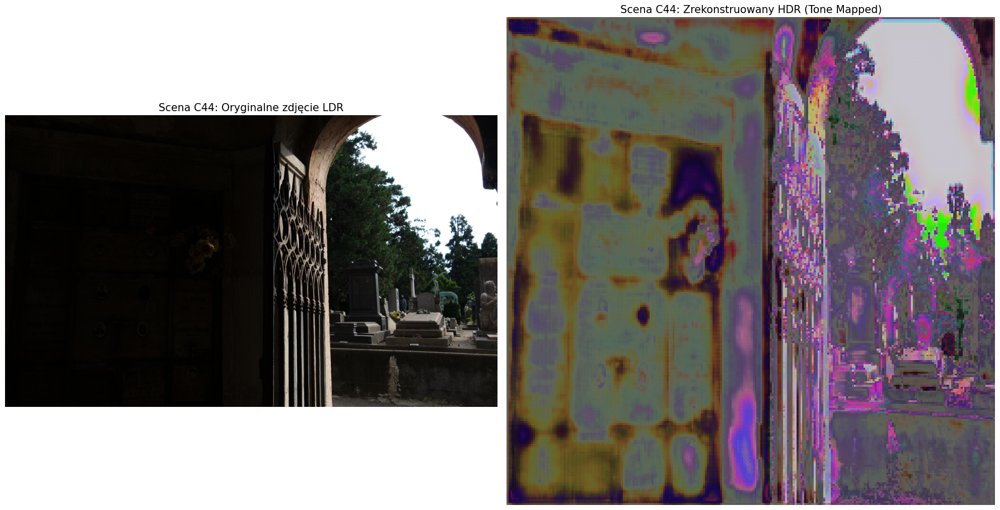

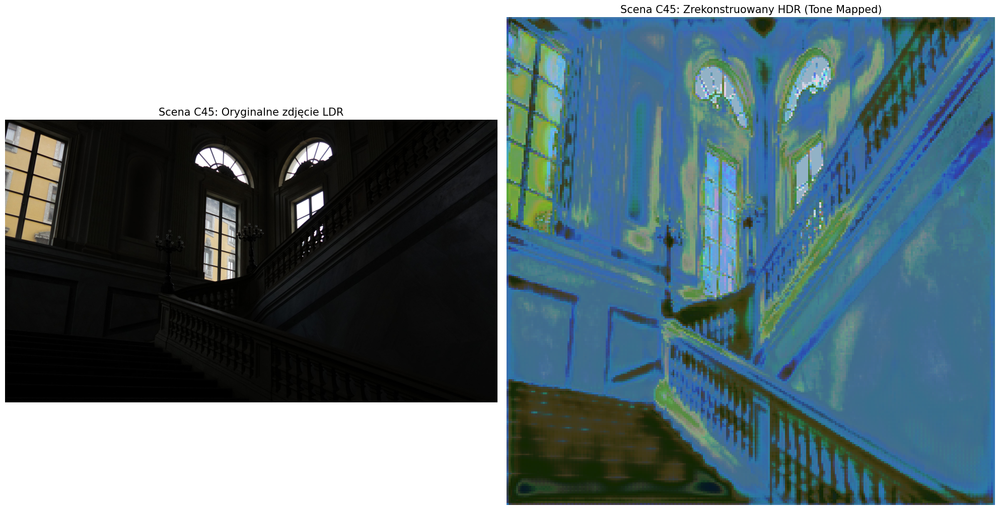

In [45]:
import matplotlib.pyplot as plt

def show_hdr_comparison(scene_id):
    model.eval()
    scene_path = os.path.join(data_path, scene_id)
    
    # 1. Pobranie danych dla konkretnej sceny
    img_files = sorted([f for f in os.listdir(scene_path) if f.lower().endswith(('.jpg', '.jpeg'))])
    base_f, _, _ = dataset.find_best_ev(scene_path, img_files)
    
    # Oryginał do wyświetlenia (JPG)
    original_ldr_img = cv2.imread(os.path.join(scene_path, base_f))
    original_ldr_img = cv2.cvtColor(original_ldr_img, cv2.COLOR_BGR2RGB)
    
    # Przygotowanie tensora dla modelu
    ldr_tensor = dataset._load_img(os.path.join(scene_path, base_f)).unsqueeze(0).to(device)
    
    with torch.no_grad():
        outputs = model(ldr_tensor)
        under_gen = outputs[:, :3, :, :]
        over_gen = outputs[:, 3:, :, :]
        
    # 2. Składanie HDR (Algorytm Debeveca z kalibracją)
    def to_cv2_uint8(t):
        t_fixed = torch.clamp(t, 0, 1)
        return (t_fixed.squeeze().permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)

    images_for_hdr = [to_cv2_uint8(under_gen), to_cv2_uint8(ldr_tensor), to_cv2_uint8(over_gen)]
    
    exif_data = dataset.get_exif(os.path.join(scene_path, base_f))
    t_base = float(exif_data['ExposureTime']) if (exif_data and 'ExposureTime' in exif_data) else 0.01
    times = np.array([t_base / (2**2.7), t_base, t_base * (2**2.7)], dtype=np.float32)
    
    calibrate = cv2.createCalibrateDebevec()
    response = calibrate.process(images_for_hdr, times)
    merge_debevec = cv2.createMergeDebevec()
    hdr_result = merge_debevec.process(images_for_hdr, times, response)
    
    # 3. Tone Mapping (Reinhard) dla ładnej wizualizacji
    tonemap = cv2.createTonemapReinhard(gamma=2.2, intensity=0.0, light_adapt=0.6, color_adapt=0.0)
    ldr_from_hdr = tonemap.process(hdr_result)
    ldr_from_hdr = np.clip(ldr_from_hdr, 0, 1) # Zabezpieczenie zakresu
    
    # 4. Wyświetlanie
    plt.figure(figsize=(20, 10))
    
    plt.subplot(1, 2, 1)
    plt.imshow(original_ldr_img)
    plt.title(f"Scena {scene_id}: Oryginalne zdjęcie LDR", fontsize=15)
    plt.axis('off')
    
    plt.subplot(1, 2, 2)
    plt.imshow(ldr_from_hdr)
    plt.title(f"Scena {scene_id}: Zrekonstruowany HDR (Tone Mapped)", fontsize=15)
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

# Wywołanie dla Twoich najlepszych scen:
show_hdr_comparison("C44")
show_hdr_comparison("C45")